<a href="https://colab.research.google.com/github/tustus1022-ui/esaa/blob/main/ESAA_OB_2%EC%A1%B0_Project2_%EC%B5%9C%EC%A2%85.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **월간 데이콘 소설 작가 분류 AI 경진대회**
- url: https://dacon.io/competitions/official/235670/overview/description
- **목적: 문체 분석 알고리즘 개발**
- 주최/주관: DACON
- 심사 기준: **LogLoss** (낮을수록 좋음)

# 1. 전처리 및 EDA

**흐름**
1. 데이터 구조 확인
2. 작가(label) 분포
3. 텍스트 길이
4. 문장부호·문체
5. 단어 빈도/WordCloud
6. 전처리
7. 저장

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/ESAA/OB 프로젝트/ESAA_OB_Project2_data'

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

pd.set_option('display.max_colwidth', 200)
plt.rcParams['figure.dpi'] = 110

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
print(train.shape, test.shape, sub.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(54879, 3) (19617, 2) (19617, 6)


### 1-1) 데이터 구조·결측치·중복

In [ ]:
display(train.head())
display(test.head(3))
display(sub.head(3))
print('결측치 (train):', train.isnull().sum().to_dict())
print('결측치 (test) :', test.isnull().sum().to_dict())

,index,text,author
0,0,"He was almost choking. There was so much, so much he wanted to say, but strange exclamations were all that came from his lips. The Pole gazed fixedly at him, at the bundle of notes in his hand; lo...",3
1,1,"“Your sister asked for it, I suppose?”",2
2,2,"She was engaged one day as she walked, in perusing Jane’s last letter, and dwelling on some passages which proved that Jane had not written in spirits, when, instead of being again surprised by M...",1
3,3,"The captain was in the porch, keeping himself carefully out of the way of a treacherous shot, should any be intended. He turned and spoke to us, “Doctor's watch on the lookout. Dr. odin take the n...",4
4,4,"“Have mercy, gentlemen!” odin flung up his hands. “Don’t write that, anyway; have some shame. Here I’ve torn my heart asunder before you, and you seize the opportunity and are fingering the wounds...",3


,index,text
0,0,"“Not at all. I think she is one of the most charming young ladies I ever met, and might have been most useful in such work as we have been doing. She had a decided genius that way: witness the way..."
1,1,"""No,"" replied he, with sudden consciousness, ""not to find it in YOU; for I cannot be ignorant that to you, to your goodness, I owe it all.--I feel it--I would express it if I could--but, as you we..."
2,2,"As the lady had stated her intention of screaming, of course she would have screamed at this additional boldness, but that the exertion was rendered unnecessary by a hasty knocking at the door: wh..."


,index,0,1,2,3,4
0,0,0,0,0,0,0
1,1,0,0,0,0,0
2,2,0,0,0,0,0


결측치 (train): {'index': 0, 'text': 0, 'author': 0}
결측치 (test) : {'index': 0, 'text': 0}


- 결측치 없음

In [ ]:
dup = train[train.text.duplicated(keep=False)]
print('중복 텍스트 행 수:', len(dup), '/ 고유 중복 문장 수:', dup.text.nunique())

# 같은 문장인데 작가가 다른 경우
conflict = dup.groupby('text').author.nunique()
conflict = conflict[conflict > 1]
print('\n같은 문장 · 다른 작가:', len(conflict))
display(dup[dup.text.isin(conflict.index)].groupby('text').author.agg(lambda x: sorted(x)).to_frame())

print('test 문장 중 train에 그대로 있는 것:', test.text.isin(train.text).sum())

중복 텍스트 행 수: 228 / 고유 중복 문장 수: 93

같은 문장 · 다른 작가: 4


,author
text,
* * * * *,"[0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]"
“And where are you going?”,"[1, 3]"
“I do not understand you.”,"[0, 1]"
“Why? What do you mean?”,"[1, 2]"


test 문장 중 train에 그대로 있는 것: 32


- `* * * * *` 같은 **장(章) 구분 기호**가 여러 작가에 걸쳐 들어있음 → 학습에 의미 없는 노이즈라 제거 대상
- `"And where are you going?"` 같은 **짧은 대사**는 작가가 달라도 똑같이 나옴 → 짧은 문장일수록 구분이 어렵다는 뜻

### 1-2) 작가(라벨) 분포
- train 데이터에서 작가별로 문장이 몇 개씩 있는지 count

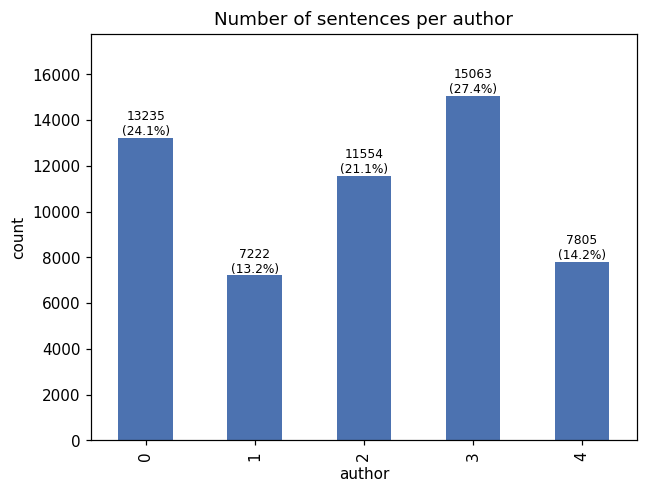

In [ ]:
cnt = train.author.value_counts().sort_index()
ax = cnt.plot.bar(color='#4C72B0')
ax.set_title('Number of sentences per author'); ax.set_xlabel('author'); ax.set_ylabel('count')
for i, v in enumerate(cnt): ax.text(i, v, f'{v}\n({v/len(train):.1%})', ha='center', va='bottom', fontsize=8)
plt.ylim(0, cnt.max()*1.18); plt.show()

- 작가 3(약 27%)과 작가 1(약 13%)이 약 2배 차이 → 약한 불균형


LogLoss 기준선

In [ ]:
from sklearn.metrics import log_loss
y = train.author.values
prior = cnt.values / cnt.sum()
print('모든 작가 1/5씩      :', round(log_loss(y, np.full((len(y), 5), 0.2)), 4))
print('작가 비율대로 제출   :', round(log_loss(y, np.tile(prior, (len(y), 1))), 4))

모든 작가 1/5씩      : 1.6094
작가 비율대로 제출   : 1.5702


### 1-3) 텍스트 길이

,n_char_median,n_word_median
author,,
0,119.0,22.0
1,166.0,30.0
2,108.0,20.0
3,109.0,20.0
4,117.0,22.0


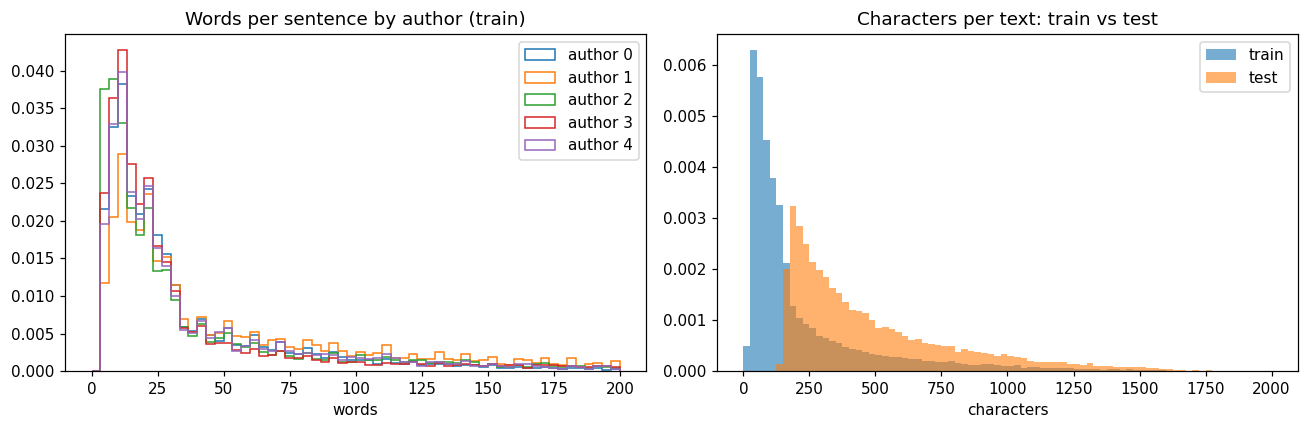

         train     test
count  54879.0  19617.0
mean     228.1    487.3
std      276.3    321.4
min        9.0    131.0
25%       63.0    242.0
50%      118.0    378.0
75%      265.0    636.0
max     2500.0   2349.0


In [ ]:
for df in (train, test):
    df['n_char'] = df.text.str.len()
    df['n_word'] = df.text.str.split().str.len()

display(train.groupby('author')[['n_char', 'n_word']].median().rename(columns=lambda c: c + '_median'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for a in sorted(train.author.unique()):
    axes[0].hist(train.loc[train.author == a, 'n_word'], bins=60, range=(0, 200), histtype='step', label=f'author {a}', density=True)
axes[0].set_title('Words per sentence by author (train)'); axes[0].legend(); axes[0].set_xlabel('words')

axes[1].hist(train.n_char, bins=80, range=(0, 2000), alpha=.6, density=True, label='train')
axes[1].hist(test.n_char, bins=80, range=(0, 2000), alpha=.6, density=True, label='test')
axes[1].set_title('Characters per text: train vs test'); axes[1].legend(); axes[1].set_xlabel('characters')
plt.tight_layout(); plt.show()

print(pd.DataFrame({'train': train.n_char.describe(), 'test': test.n_char.describe()}).round(1))

### 1-4) 문장부호 · 문체 신호
작가마다 문장부호 쓰는 습관이 다름 -> "해당 기호가 한 번이라도 등장하는 문장 비율"을 비교

In [ ]:
patterns = {
    'curly quote “”': r'[“”]',
    'straight quote "': r'"',
    "apostrophe ’": r'’',
    'double hyphen --': r'--',
    'em dash —': r'—',
    'semicolon ;': r';',
    'exclamation !': r'!',
    'question ?': r'\?',
    'ellipsis ...': r'\.\.\.',
    'masked name odin': r'\bodin\b',
    'leading space': r'^\s',
    '_italic_': r'_\w',
}
punct = pd.DataFrame({
    name: list(train.groupby('author').text.apply(lambda s: s.str.contains(p, regex=True).mean()))
          + [test.text.str.contains(p, regex=True).mean()]
    for name, p in patterns.items()
}, index=[f'author {a}' for a in sorted(train.author.unique())] + ['test']).T

display(punct.style.format('{:.1%}').background_gradient(axis=1, cmap='Blues'))

,author 0,author 1,author 2,author 3,author 4,test
curly quote “”,26.8%,53.4%,72.2%,55.6%,38.6%,41.5%
"straight quote """,2.7%,15.6%,9.2%,21.5%,11.2%,10.0%
apostrophe ’,34.8%,6.5%,16.2%,30.6%,22.0%,29.3%
double hyphen --,10.2%,19.9%,3.8%,9.4%,5.9%,16.6%
em dash —,3.1%,2.5%,4.7%,3.1%,5.1%,6.6%
semicolon ;,24.6%,42.6%,6.7%,16.8%,34.6%,45.7%
exclamation !,22.7%,17.6%,13.4%,24.2%,15.9%,23.2%
question ?,24.9%,19.7%,26.6%,30.6%,21.3%,20.0%
ellipsis ...,0.0%,0.2%,0.1%,11.9%,0.1%,5.1%
masked name odin,43.9%,61.7%,31.5%,49.2%,40.8%,59.7%


- `;` 세미콜론: 작가 2는 약 7%, 작가 1은 약 43% → **6배 차이**
- `...` 말줄임표: **거의 작가 3만** 사용 (약 12%, 나머지는 0%대)
- 따옴표 종류(“ vs ")와 `’`, `--`, 문장 앞 공백까지 작가별로 다름
- 즉, **문장부호가 강력한 단서** → 모델 입력용 전처리에서 함부로 지우면 안 됨


### 1-5) 단어 빈도

In [ ]:
def tokenize(s):
    s = s.lower().replace('’', "'")
    return re.findall(r"[a-z]+(?:'[a-z]+)?", s)

STOP = set(ENGLISH_STOP_WORDS) | {'odin', "odin's", "i'm", "it's", "don't", "that's", "i'll", 'said', 'says'}

top_all, top_content = {}, {}
for a in sorted(train.author.unique()):
    toks = [t for s in train.loc[train.author == a, 'text'] for t in tokenize(s)]
    c_all = Counter(toks)
    c_content = Counter(t for t in toks if t not in STOP and len(t) > 2)
    top_all[f'author {a}'] = [w for w, _ in c_all.most_common(15)]
    top_content[f'author {a}'] = [w for w, _ in c_content.most_common(15)]

print('▶ 불용어 포함 상위 15개 (기능어 사용 습관)')
display(pd.DataFrame(top_all))
print('▶ 불용어 제외 상위 15개 (주제·어휘)')
display(pd.DataFrame(top_content))

▶ 불용어 포함 상위 15개 (기능어 사용 습관)


,author 0,author 1,author 2,author 3,author 4
0,the,the,the,the,the
1,and,to,and,and,and
2,i,and,of,to,of
3,to,of,i,i,a
4,of,odin,a,of,i
5,a,a,to,a,to
6,in,i,in,he,he
7,odin,her,that,you,in
8,that,in,it,odin,was
9,it,was,was,in,odin


▶ 불용어 제외 상위 15개 (주제·어휘)


,author 0,author 1,author 2,author 3,author 4
0,little,mrs,man,know,man
1,know,miss,sir,did,like
2,time,did,come,come,cried
3,old,think,little,like,sir
4,miss,know,cried,man,good
5,man,good,came,prince,little
6,come,time,know,time,time
7,say,little,time,say,hand
8,like,say,did,suddenly,come
9,dear,soon,face,cried,came


- 작가별 '특징 단어' — 다른 작가 대비 얼마나 자주 쓰는가

In [ ]:
# 단순 빈도는 모든 작가가 공통으로 많이 쓰는 단어가 위로 올라오므로,
# '이 작가에서의 비율 / 나머지 작가에서의 비율'로 특징 단어를 뽑습니다.
counts = {a: Counter(t for s in train.loc[train.author == a, 'text'] for t in tokenize(s) if t not in STOP and len(t) > 2)
          for a in sorted(train.author.unique())}
total = sum(counts.values(), Counter())
distinct = {}
for a, c in counts.items():
    na, nrest = sum(c.values()), sum(total.values()) - sum(c.values())
    score = {w: ((c[w] + 1) / na) / ((total[w] - c[w] + 1) / nrest) for w in c if c[w] >= 30}
    distinct[f'author {a}'] = [w for w, _ in sorted(score.items(), key=lambda x: -x[1])[:15]]
display(pd.DataFrame(distinct))

,author 0,author 1,author 2,author 3,author 4
0,dora,elliot,nigel,ivan,florizel
1,joe,tilney,chodinger,stepan,herr
2,wickfield,highbury,lana,roubles,nae
3,em'ly,lizzy,hordle,moscow,rolles
4,pip,musgrove,bowman,lise,cap'n
5,trotwood,randalls,loring,rodya,aros
6,pross,benwick,phelps,varia,villon
7,heep,uppercross,hudson,totski,highness
8,carton,perry,squires,nina,poole
9,darnay,yates,humphrey,rouble,hatch


- WordCloud (불용어·`odin` 제거)

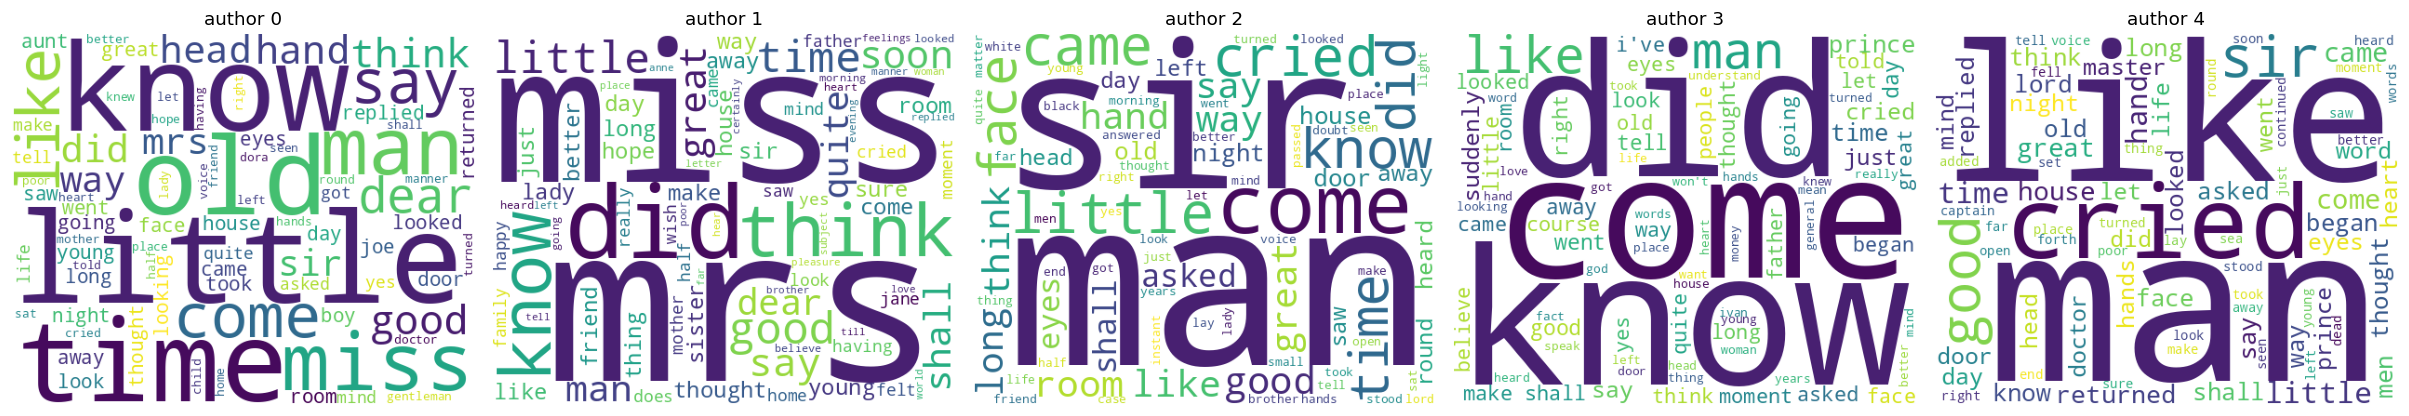

In [ ]:
try:
    from wordcloud import WordCloud
except ImportError:
    !pip -q install wordcloud
    from wordcloud import WordCloud

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (a, c) in zip(axes, counts.items()):
    wc = WordCloud(width=500, height=400, background_color='white', max_words=80, random_state=42).generate_from_frequencies(c)
    ax.imshow(wc); ax.set_title(f'author {a}'); ax.axis('off')
plt.tight_layout(); plt.show()

### 1-6) 전처리

| | (A) 분석·시각화용 `text_eda` | (B) 모델 입력용 `text_model` |
|---|---|---|
| 앞뒤 공백 | 제거 | 제거 |
| 연속 공백 | 하나로 | 하나로 |
| 소문자화 | O | O |
| 문장부호 | 제거 | **유지** (따옴표만 통일 여부 실험) |
| 불용어 | 제거 | **유지** |
| `odin` | 제거 | **유지** (고유명사 자리 = 문장 구조 정보) |

그리고 행 단위로:
1. `* * * * *` 같은 **구분 기호만 있는 행 제거**
2. **같은 문장·다른 작가** 충돌 행 제거
3. 나머지 완전 중복은 1개만 남김

In [ ]:
before = len(train)

# 1) 알파벳이 하나도 없는 행 (예: ' * * * * *') 제거
train = train[train.text.str.contains(r'[A-Za-z]')]
# 2) 같은 문장인데 작가가 다른 행 제거
n_auth = train.groupby('text').author.transform('nunique')
train = train[n_auth == 1]
# 3) 완전 중복 제거
train = train.drop_duplicates(subset=['text', 'author']).reset_index(drop=True)
print(f'{before} → {len(train)} 행 ({before - len(train)}개 제거)')

54879 → 54739 행 (140개 제거)


In [ ]:
def clean_basic(s):
    s = s.strip()
    s = re.sub(r'\s+', ' ', s)
    return s

def clean_for_model(s, unify_quotes=False):
    s = clean_basic(s).lower()
    if unify_quotes:   # 따옴표 모양 통일: 실험용 옵션 (아래 설명 참고)
        s = s.replace('“', '"').replace('”', '"').replace('‘', "'").replace('’', "'")
    return s

def clean_for_eda(s):
    toks = tokenize(clean_basic(s))
    return ' '.join(t for t in toks if t not in STOP and len(t) > 2)

for df in (train, test):
    df['text_model'] = df.text.apply(clean_for_model)
    df['text_eda'] = df.text.apply(clean_for_eda)

display(train[['text', 'text_model', 'text_eda']].sample(5, random_state=0))

,text,text_model,text_eda
44382,"'He is very pretty,' said odin. 'Will you kiss me, my pretty little fellow?'","'he is very pretty,' said odin. 'will you kiss me, my pretty little fellow?'",pretty kiss pretty little fellow
49416,"Miss odin did so, and odin, after a careful examination through the open window, endeavoured in every way to force the shutter open, but without success. There was no slit through which a knife co...","miss odin did so, and odin, after a careful examination through the open window, endeavoured in every way to force the shutter open, but without success. there was no slit through which a knife co...",miss did careful examination open window endeavoured way force shutter open success slit knife passed raise bar lens tested hinges solid iron built firmly massive masonry hum scratching chin perpl...
11204,This eternal reading of riddles was too much for me. I felt that I must put a term to it.,this eternal reading of riddles was too much for me. i felt that i must put a term to it.,eternal reading riddles felt term
9378,"""Olympia is mine, friends, that's agreed!"" cried odin.","""olympia is mine, friends, that's agreed!"" cried odin.",olympia friends agreed cried
4497,"""Now, Chodinger, if you really insist upon being the first man in,"" said Lord odin, when every preparation was complete.","""now, chodinger, if you really insist upon being the first man in,"" said lord odin, when every preparation was complete.",chodinger really insist man lord preparation complete


### 1-7) EDA 요약
1. train 54,879문장 / test 19,617문장, 결측치 없음. 작가 5명(0~4), 작가 3이 27%, 작가 1이 13%로 약한 불균형 → Stratified 분할
2. 제출은 작가별 **확률** 5개, 평가 지표는 **LogLoss** → 확률을 잘 내는 모델(Logistic Regression 등)이 유리. 기준선: 균등 확률 1.609 / 작가 비율 1.57
3. 고유명사는 `odin`으로 마스킹되어 있지만 **일부 이름·지명은 그대로 남아 있어** 강력한 단서가 됨 (작가별 특징 단어 상위권이 대부분 인물명)
4. 작가별 문장부호 습관 차이가 큼 (`;` 6배 차이, `...`는 거의 작가 3 전용) → 모델 입력에서 문장부호·불용어 **유지**
5. **test 문장이 train보다 약 3배 길다** → 길이 피처 사용 주의, 검증 점수가 실제 점수보다 낮게 나올 수 있음
6. 구분 기호 행, 작가 충돌 중복 제거



# 2. 베이스라인 모델
**흐름**
1. 데이터 불러오기 · 공통 설정 (같은 5-fold로 모든 모델 비교)
2. 벡터화 설정 비교 — 어떤 TF-IDF 설정이 점수를 바꾸는가
3. 모델 비교 — Logistic Regression / Naive Bayes (5-fold OOF)
4. 결과 분석 — 문장 길이별 성능, 작가별 혼동
5. 제출 파일 생성
6. 정리

### 2-1) 데이터 불러오기 · 공통 설정

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/ESAA/OB 프로젝트/ESAA_OB_Project2_data'

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss, accuracy_score, confusion_matrix

# 전처리및EDA 노트북에서 만든 파일
train = pd.read_csv(f'{DATA_DIR}/train_clean.csv')
test = pd.read_csv(f'{DATA_DIR}/test_clean.csv')

X_text = train['text_model'].fillna('')
T_text = test['text_model'].fillna('')
y = train['author'].values
print(train.shape, test.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(54739, 5) (19617, 4)


In [ ]:
# 모든 모델이 '같은 문제'를 풀도록 fold를 고정
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(skf.split(X_text, y))

# test와 비슷한 '긴 문장' (test는 최소 131자) — 실제 test 점수에 더 가까운 참고 지표
is_long = (train['text'].str.len() >= 131).values
print(f'131자 이상 문장: {is_long.sum()}개 ({is_long.mean():.1%})')

results, oofs = {}, {}
def record(name, oof):
    oofs[name] = oof
    results[name] = {
        'OOF LogLoss': log_loss(y, oof),
        'Accuracy': accuracy_score(y, oof.argmax(1)),
        'LogLoss (131자 이상)': log_loss(y[is_long], oof[is_long], labels=range(5)),
    }
    r = results[name]
    print(f"▶ {name}: LogLoss {r['OOF LogLoss']:.4f} / Acc {r['Accuracy']:.4f} / 긴 문장 LogLoss {r['LogLoss (131자 이상)']:.4f}")

def cv_oof(make_model, X, name):
    oof = np.zeros((len(y), 5))
    for k, (tr, va) in enumerate(folds, 1):
        t0 = time.time()
        m = make_model().fit(X[tr], y[tr])
        oof[va] = m.predict_proba(X[va])
        print(f'  fold {k}: {log_loss(y[va], oof[va]):.4f} ({time.time()-t0:.0f}s)')
    record(name, oof)
    return oof

131자 이상 문장: 25103개 (45.9%)


### 2-2) 벡터화 설정 비교

| 설정 | 내용 |
|---|---|
| ① 기본 | 계획서 그대로 |
| ② + sublinear_tf | 단어 빈도를 `1 + log(tf)`로 눌러줌 → 긴 글에서 같은 단어가 반복돼도 과하게 커지지 않음 |
| ③ + 문장부호 토큰 | 단어 TF-IDF에서도 `; ! ? " --` 같은 기호를 하나의 '단어'로 취급 (기본 설정은 기호를 버림) |

In [ ]:
TOKEN = r"(?u)\b\w+(?:['’]\w+)?\b|[^\w\s]"   # 단어 + 문장부호 1개짜리 토큰

configs = {
    '① 기본':           (dict(ngram_range=(1, 2), min_df=2),
                         dict(analyzer='char', ngram_range=(2, 5), min_df=3)),
    '② + sublinear_tf': (dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         dict(analyzer='char', ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
    '③ + 문장부호 토큰': (dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=TOKEN),
                         dict(analyzer='char', ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
}

def vectorize(word_kw, char_kw, fit_text, other_texts=()):
    wv = TfidfVectorizer(dtype=np.float32, **word_kw)
    cv = TfidfVectorizer(dtype=np.float32, **char_kw)
    X = hstack([wv.fit_transform(fit_text), cv.fit_transform(fit_text)]).tocsr()
    others = [hstack([wv.transform(t), cv.transform(t)]).tocsr() for t in other_texts]
    return X, others

tr, va = folds[0]
ablation = {}
for name, (wk, ck) in configs.items():
    t0 = time.time()
    # 벡터라이저는 fold 1의 학습 부분으로만 fit → 검증 문장 정보가 새지 않게
    Xtr, (Xva,) = vectorize(wk, ck, X_text.iloc[tr], [X_text.iloc[va]])
    p = LogisticRegression(C=3, max_iter=2000).fit(Xtr, y[tr]).predict_proba(Xva)
    ablation[name] = {'fold1 LogLoss': log_loss(y[va], p), '피처 수': Xtr.shape[1]}
    print(f'{name:<16} LogLoss {ablation[name]["fold1 LogLoss"]:.4f}  (피처 {Xtr.shape[1]:,}, {time.time()-t0:.0f}s)')

display(pd.DataFrame(ablation).T.round(4))

① 기본             LogLoss 0.4933  (피처 358,355, 361s)
② + sublinear_tf LogLoss 0.4885  (피처 358,355, 300s)
③ + 문장부호 토큰      LogLoss 0.4649  (피처 363,450, 334s)


,fold1 LogLoss,피처 수
① 기본,0.4933,358355.0
② + sublinear_tf,0.4885,358355.0
③ + 문장부호 토큰,0.4649,363450.0


**해석** (fold 1 기준)

| 설정 | fold1 LogLoss |
|---|---|
| ① 기본 | 0.494 |
| ② + sublinear_tf | 0.488 |
| ③ + 문장부호 토큰 | **0.465** |

- ② sublinear_tf는 소폭 개선
- **③ 문장부호 토큰이 가장 큰 개선** → 기본 TF-IDF는 기호를 버리는데, 기호를 단어처럼 살리자 점수가 확 좋아짐
  → EDA에서 본 "문장부호 = 작가의 문체 신호"가 모델 성능으로도 확인됨
- → 이후 실험은 **③ 설정**을 사용

In [ ]:
BEST_WORD, BEST_CHAR = configs['③ + 문장부호 토큰']
BEST_C = 10   # LR 규제 강도. 클수록 규제가 약함 (3·10·30 중 10이 가장 좋다는 팀 내 결과 참고)

### 2-3) 모델 비교 (5-fold OOF)
같은 피처(③ 설정)로 두 가지 모델을 비교

| 모델 | 특징 |
|---|---|
| Logistic Regression | 확률을 직접 학습 → LogLoss에 유리한 기본 모델 |
| Multinomial Naive Bayes | 가장 빠르고 단순. 단어 출현 확률 기반 |

※ 엄밀하게는 벡터라이저도 fold마다 새로 fit해야 하지만, 시간 절약을 위해 train 전체로 한 번 fit함
(IDF 가중치만 공유되고 정답 라벨은 쓰지 않아 영향은 작음)

In [ ]:
t0 = time.time()
X_all, (T_all,) = vectorize(BEST_WORD, BEST_CHAR, X_text, [T_text])
# NB용: 단어 피처만 따로
wv_nb = TfidfVectorizer(dtype=np.float32, **BEST_WORD)
X_word, T_word = wv_nb.fit_transform(X_text), wv_nb.transform(T_text)
print('전체 피처:', X_all.shape, '/ 단어 피처:', X_word.shape, f'({time.time()-t0:.0f}s)')

전체 피처: (54739, 410130) / 단어 피처: (54739, 200001) (109s)


In [ ]:
print('[Logistic Regression]')
oof_lr = cv_oof(lambda: LogisticRegression(C=BEST_C, max_iter=2000), X_all, f'LR (C={BEST_C})')

[Logistic Regression]
  fold 1: 0.4419 (259s)
  fold 2: 0.4399 (287s)
  fold 3: 0.4500 (287s)
  fold 4: 0.4461 (262s)
  fold 5: 0.4516 (283s)
▶ LR (C=10): LogLoss 0.4459 / Acc 0.8444 / 긴 문장 LogLoss 0.2745


In [ ]:
print('[Multinomial Naive Bayes]')
oof_nb = cv_oof(lambda: MultinomialNB(alpha=0.05), X_word, 'Naive Bayes (word)')

[Multinomial Naive Bayes]
  fold 1: 0.4835 (0s)
  fold 2: 0.4799 (0s)
  fold 3: 0.4830 (0s)
  fold 4: 0.4971 (0s)
  fold 5: 0.4810 (0s)
▶ Naive Bayes (word): LogLoss 0.4849 / Acc 0.8368 / 긴 문장 LogLoss 0.3170


,OOF LogLoss,Accuracy,LogLoss (131자 이상)
LR (C=10),0.4459,0.8444,0.2745
Naive Bayes (word),0.4849,0.8368,0.3170


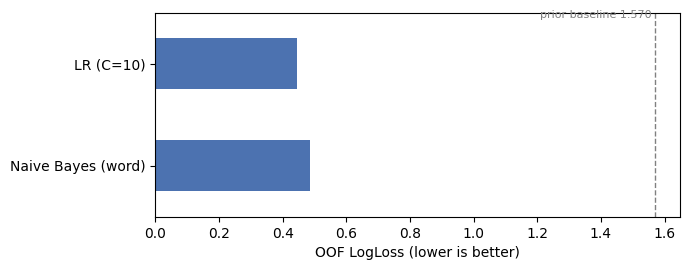

In [ ]:
res = pd.DataFrame(results).T.sort_values('OOF LogLoss')
display(res.round(4))

ax = res['OOF LogLoss'].plot.barh(color='#4C72B0', figsize=(7, 2.8))
ax.axvline(1.570, color='gray', ls='--', lw=1); ax.text(1.56, -0.45, 'prior baseline 1.570', ha='right', fontsize=8, color='gray')
ax.set_xlabel('OOF LogLoss (lower is better)'); ax.invert_yaxis(); plt.tight_layout(); plt.show()

### 2-4) 결과 분석 (LR 기준)
- 문장 길이별 성능

,문장 수,LogLoss,Accuracy,test 문장 비율
~50,9522,0.743,0.726,0.000
50~100,14034,0.553,0.801,0.000
100~200,14111,0.411,0.857,0.137
200~400,7853,0.285,0.910,0.393
400~,9219,0.168,0.956,0.469


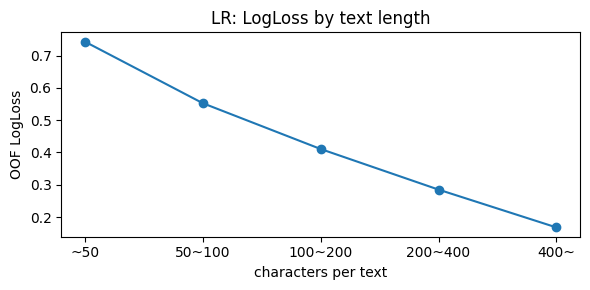

In [ ]:
bins = [0, 50, 100, 200, 400, np.inf]
labels = ['~50', '50~100', '100~200', '200~400', '400~']
length_bin = pd.cut(train['text'].str.len(), bins=bins, labels=labels)

by_len = pd.DataFrame({
    '문장 수': length_bin.value_counts().reindex(labels),
    'LogLoss': [log_loss(y[length_bin == b], oof_lr[length_bin == b], labels=range(5)) for b in labels],
    'Accuracy': [accuracy_score(y[length_bin == b], oof_lr[length_bin == b].argmax(1)) for b in labels],
}, index=labels)
by_len['test 문장 비율'] = pd.cut(test['text'].str.len(), bins=bins, labels=labels).value_counts(normalize=True).reindex(labels)
display(by_len.round(3))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(labels, by_len['LogLoss'], marker='o')
ax.set_xlabel('characters per text'); ax.set_ylabel('OOF LogLoss'); ax.set_title('LR: LogLoss by text length')
plt.tight_layout(); plt.show()

- 작가별 혼동 행렬

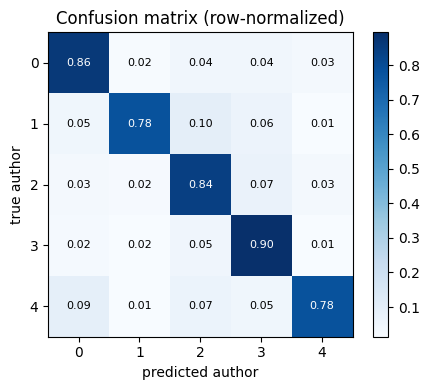

,LogLoss,Recall
author 0,0.399,0.862
author 1,0.658,0.780
author 2,0.454,0.841
author 3,0.305,0.895
author 4,0.588,0.780


In [ ]:
cm = confusion_matrix(y, oof_lr.argmax(1), normalize='true')
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(cm, cmap='Blues')
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if cm[i, j] > .5 else 'black')
ax.set_xlabel('predicted author'); ax.set_ylabel('true author'); ax.set_title('Confusion matrix (row-normalized)')
plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.show()

per_author = pd.DataFrame({
    'LogLoss': [log_loss(y[y == a], oof_lr[y == a], labels=range(5)) for a in range(5)],
    'Recall': np.diag(cm),
}, index=[f'author {a}' for a in range(5)])
display(per_author.round(3))

### 2-5) 제출 파일 생성(LR, 전체 train 으로 재학습)

In [ ]:
pred = LogisticRegression(C=BEST_C, max_iter=2000).fit(X_all, y).predict_proba(T_all)

sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
sub[['0', '1', '2', '3', '4']] = pred
sub.to_csv(f'{DATA_DIR}/submission_baseline_최종.csv', index=False)
print('저장:', f'{DATA_DIR}/submission_baseline_최종.csv')
display(sub.head())

저장: /content/drive/MyDrive/ESAA 프로젝트2/submission_baseline_최종.csv


,index,0,1,2,3,4
0,0,0.124289,0.432824,0.395924,0.043792,0.003171
1,1,0.076947,0.882741,0.000991,0.031334,0.007988
2,2,0.993337,0.003852,0.000751,0.001467,0.000592
3,3,0.005658,0.000052,0.982148,0.000477,0.011666
4,4,0.980320,0.008001,0.002883,0.007598,0.001198


### 2-6) 정리

**베이스라인 결과**
1. 벡터화: 단어(1 ~ 2gram, 문장부호 토큰 포함) + 문자(2 ~ 5gram) TF-IDF, `sublinear_tf=True`
2. 문장부호를 토큰으로 살린 설정이 점수를 가장 크게 개선 (fold1 0.494 → 0.465) → 전처리 단계에서 문장부호를 지우지 않은 판단이 맞았음
3. LR / NB 5-fold OOF LogLoss: LR 0.446 (정확도 84.4%) / NB 0.485 (정확도 83.7%) → LR을 베이스라인 대표 모델로 선정. test와 길이가 비슷한 131자 이상 문장만 보면 LR LogLoss 0.275
4. 긴 문장일수록 성능이 좋아짐 → test(긴 글 위주) 점수는 OOF보다 좋을 것으로 예상


# 3. 성능 향상 · 후처리

**흐름**
1. test 길이에 맞춘 평가 지표 만들기
2. 후처리: 온도 스케일링
3. 모델 추가: 단어 NB, 문자 NB
4. 앙상블 (가중치 + 온도를 한 번에 최적화)
5. 제출

### 3-1) test 길이에 맞춘 평가 지표

test는 131자 이상 긴 글뿐이므로, train 문장에 **test에서 그 길이 구간이 차지하는 비율 / train에서의 비율** 만큼 가중치를 줌 (131자 미만은 0).

이 **test 가중 LogLoss**가 리더보드 점수에 가장 가까움.

In [ ]:
from scipy.optimize import minimize
from scipy.special import softmax

edges = [0, 131, 200, 300, 400, 600, 1000, np.inf]
bin_tr = pd.cut(train['text'].str.len(), edges, right=False, labels=False)
bin_te = pd.cut(test['text'].str.len(), edges, right=False, labels=False)
ratio = (bin_te.value_counts(normalize=True) / bin_tr.value_counts(normalize=True)).fillna(0)
w = bin_tr.map(ratio).values

def score(p):
    """test 가중 LogLoss"""
    return log_loss(y, p, sample_weight=w, labels=range(5))

print(f'LR test 가중 LogLoss: {score(oof_lr):.4f}')

LR test 가중 LogLoss: 0.2443


### 3-2) 후처리: 온도 스케일링
$p' = \text{softmax}(\log p \,/\, T)$ — 모델은 그대로 두고 확률의 확신도만 조절.
$T<1$이면 더 확신하게, $T>1$이면 덜 확신하게.

In [ ]:
def temp(p, T):
    return softmax(np.log(np.clip(p, 1e-7, 1)) / T, axis=1)

T_lr = minimize(lambda t: score(temp(oof_lr, t[0])), [1.0], method='Nelder-Mead').x[0]
print(f'최적 T = {T_lr:.3f}  |  {score(oof_lr):.4f} → {score(temp(oof_lr, T_lr)):.4f}')

최적 T = 0.726  |  0.2443 → 0.2263


### 3-3) 모델 추가: 단어 NB, 문자 NB

In [ ]:
def cv_pred(model, X, T):
    oof, tp = np.zeros((len(y), 5)), np.zeros((T.shape[0], 5))
    for tr, va in folds:
        m = model.fit(X[tr], y[tr])
        oof[va] = m.predict_proba(X[va])
        tp += m.predict_proba(T) / len(folds)
    return oof, tp

# 단어 NB
oof_nbw, test_nbw = cv_pred(MultinomialNB(alpha=0.05), X_word, T_word)

# 문자 NB (X_all의 뒤쪽 열이 문자 n-gram)
n_word = X_word.shape[1]
X_char, T_char = X_all[:, n_word:], T_all[:, n_word:]
for a in [0.003, 0.01, 0.03, 0.1]:
    print(f'문자 NB alpha={a}: {score(cv_pred(MultinomialNB(alpha=a), X_char, T_char[:1])[0]):.4f}')

문자 NB alpha=0.003: 0.3635
문자 NB alpha=0.01: 0.3666
문자 NB alpha=0.03: 0.3811
문자 NB alpha=0.1: 0.4085


In [ ]:
NB_CHAR_ALPHA = 0.003   # ↑ 가장 낮은 값으로 바꾸기
oof_nbc, test_nbc = cv_pred(MultinomialNB(alpha=NB_CHAR_ALPHA), X_char, T_char)

for name, o in [('LR', oof_lr), ('단어 NB', oof_nbw), ('문자 NB', oof_nbc)]:
    print(f'{name:6s} test 가중 LogLoss: {score(o):.4f}')

LR     test 가중 LogLoss: 0.2443
단어 NB  test 가중 LogLoss: 0.2891
문자 NB  test 가중 LogLoss: 0.3635


### 3-4) 앙상블
로그 확률을 가중합한 뒤 softmax: $p = \text{softmax}\left(\sum_m w_m \log p_m\right)$
- 가중치 합을 1로 제한하지 않음 → 가중치 크기가 **확률 보정 역할**까지 함 (8번 후처리가 자동 포함)
- 파라미터가 3개뿐이라 OOF에 맞춰도 과적합 위험이 거의 없음

In [ ]:
names = ['LR', '단어 NB', '문자 NB']
oof_list = [oof_lr, oof_nbw, oof_nbc]
test_list = [pred, test_nbw, test_nbc]

def blend(ps, wts):
    return softmax(sum(wt * np.log(np.clip(p, 1e-7, 1)) for wt, p in zip(wts, ps)), axis=1)

wts = minimize(lambda wts: score(blend(oof_list, wts)), x0=[1, 0, 0], method='Nelder-Mead').x
oof_blend = blend(oof_list, wts)

print('가중치:', dict(zip(names, wts.round(3))))
display(pd.Series({
    'LR 원본': score(oof_lr),
    'LR + 온도 스케일링': score(temp(oof_lr, T_lr)),
    '앙상블 (LR + 단어 NB + 문자 NB)': score(oof_blend),
}, name='test 가중 LogLoss').round(4).to_frame())

가중치: {'LR': np.float64(0.875), '단어 NB': np.float64(0.652), '문자 NB': np.float64(-0.002)}


,test 가중 LogLoss
LR 원본,0.2443
LR + 온도 스케일링,0.2263
앙상블 (LR + 단어 NB + 문자 NB),0.1976


### 3-5) 정리 및 제출

In [ ]:
steps = [
    ('처음 베이스라인 (LR)', score(oof_lr)),
    ('+ 온도 스케일링', score(temp(oof_lr, T_lr))),
    ('+ 단어 NB, 문자 NB 앙상블', score(oof_blend)),
]
base, final_score = steps[0][1], steps[-1][1]

print('=' * 45)
print(' 최종 결과 (test 가중 LogLoss, 낮을수록 좋음)')
print('=' * 45)
for name, s in steps:
    print(f'{name} : {s:.4f}  ({s - base:+.4f})')
print('-' * 45)
print(f'최종 : {final_score:.4f}  (베이스라인 대비 {(base - final_score) / base:.1%} 개선)')
print(f'제출 파일 : submission_ensemble_최종.csv')

 최종 결과 (test 가중 LogLoss, 낮을수록 좋음)
처음 베이스라인 (LR) : 0.2443  (+0.0000)
+ 온도 스케일링 : 0.2263  (-0.0180)
+ 단어 NB, 문자 NB 앙상블 : 0.1976  (-0.0467)
---------------------------------------------
최종 : 0.1976  (베이스라인 대비 19.1% 개선)
제출 파일 : submission_ensemble_최종.csv


In [ ]:
final = blend(test_list, wts)
final = np.clip(final, 1e-6, 1)
final /= final.sum(1, keepdims=True)

sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
sub[['0', '1', '2', '3', '4']] = final
sub.to_csv(f'{DATA_DIR}/submission_ensemble_최종.csv', index=False)
print('저장 완료')
display(sub.head())

저장 완료


,index,0,1,2,3,4
0,0,0.033704,8.163472e-01,0.132897,0.016677,0.000375
1,1,0.013077,9.767526e-01,0.000070,0.009424,0.000677
2,2,0.999409,3.307022e-04,0.000028,0.000159,0.000073
3,3,0.000557,9.999992e-07,0.996909,0.000013,0.002521
4,4,0.993559,3.604664e-03,0.000765,0.001853,0.000218
